In [1]:
import os, sys
cur_directory = os.getcwd()
project_folder = os.path.abspath(os.path.join(cur_directory, os.pardir, os.pardir))
save_directory = os.path.join(cur_directory, 'saved')
sys.path.append(os.path.join(project_folder, 'analysis-suite'))

In [2]:
import numpy as np
import matplotlib as mpl
from matplotlib import pyplot as plt
import analyses as als
import datasets as ds
import models as mds
import tools
from random import sample
from tqdm import tqdm
from argparse import Namespace
from time import gmtime, strftime
import pickle
import cv2

In [3]:
mov_ind = 0

In [4]:
# Load neural data
data_path = os.path.join(project_folder, 'data', 'nat_scenes_data')
D = ds.DataNatScenes(data_path, mov_ind=mov_ind)
trim = 0
D.trim(trim + 3)

In [5]:
# Load in movie as dataset
mov_filenames = ['tree', 'water', 'grasses', 'fish', 'opticflow']
mov_path = os.path.join(project_folder, 'data', f'MultipleMoviesStim_{mov_ind+1}_{mov_filenames[mov_ind]}.avi')

cap = cv2.VideoCapture(mov_path)
frames = []
grays = []
while True:
    ret, frame = cap.read()
    if not ret:
        break
    gray = cv2.cvtColor(frame, cv2.COLOR_BGR2GRAY)
    grays.append(gray)
    frames.append(gray.flatten().astype(float))
cap.release()

mov_dims = gray.shape
frame_H, frame_W = mov_dims
mov_array = np.array(frames).T  # (H*W, n_frames)

M = ds.Dataset(mov_array)
# M.trim(3-trim)
M.trim(trim)
print(f'Movie shape (pixels x frames): {M.X.shape}')
print(f'Neural data shape (cells x time): {D.X.shape}')

Movie shape (pixels x frames): (118336, 600)
Neural data shape (cells x time): (93, 99600)


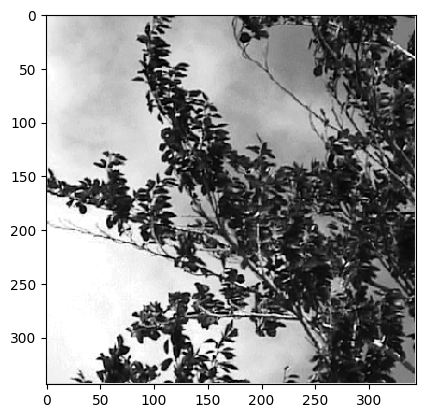

In [6]:
plt.imshow(grays[-1], cmap='Greys_r')

In [88]:
# Determine receptive fields via spike-triggered average
# Average neural response across trials: (N_cells, T_per_trial)
mean_response = np.mean(np.stack([d.X for d in D.data], axis=2), axis=2)

# RF[i, j] = sum_t( mean_response[i,t] * M[j,t] ) / total_spikes[i]
# Shape: (N_cells, H*W)
total_spikes = mean_response.sum(axis=1, keepdims=True)  # (N_cells, 1)
RF = (mean_response @ M.X.T) / total_spikes              # (N_cells, H*W)

RF_images = RF.reshape(D.N, frame_H, frame_W)            # (N_cells, H, W)
print(f'RF shape: {RF_images.shape}')

ValueError: matmul: Input operand 1 has a mismatch in its core dimension 0, with gufunc signature (n?,k),(k,m?)->(n?,m?) (size 600 is different from 1200)

In [79]:
RF_images

array([[[205.        , 205.        , 205.        , ..., 205.        ,
         205.        , 205.        ],
        [205.        , 111.40666765, 113.35923043, ..., 127.01101483,
         126.55999413, 205.        ],
        [205.        , 111.56689675, 113.01865178, ..., 126.73300044,
         127.29813482, 205.        ],
        ...,
        [205.        ,  78.30165957,  78.07490087, ...,  69.92039947,
          69.78822147, 205.        ],
        [205.        ,  78.49933911,  77.51505361, ...,  69.49126157,
          69.53605522, 205.        ],
        [205.        , 205.        , 205.        , ..., 205.        ,
         205.        , 205.        ]],

       [[205.        , 205.        , 205.        , ..., 205.        ,
         205.        , 205.        ],
        [205.        ,  96.92862976,  96.51951658, ...,  76.45369917,
          76.58827372, 205.        ],
        [205.        ,  95.87473461,  95.3803691 , ...,  77.64004573,
          78.12134575, 205.        ],
        ...,


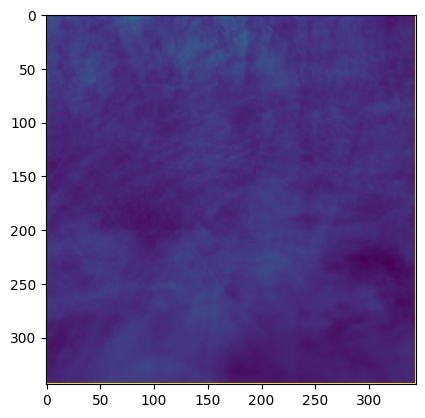

In [83]:
plt.imshow(RF[60,:].reshape(*mov_dims))

In [39]:
mean_response.shape

(93, 1183)

In [35]:
# Compute mask by thresholding receptive field
threshold = 0.4  # fraction of each cell's peak |RF| to use as cutoff

masks_flat = np.zeros((D.N, frame_H * frame_W), dtype=bool)
for i in range(D.N):
    rf_power = np.abs(RF[i])
    masks_flat[i] = rf_power > threshold * rf_power.max()

# Union across cells: pixels within any cell's RF
mov_mask = masks_flat.any(axis=0)  # (H*W,)
print(f'Pixels retained: {mov_mask.sum()} / {mov_mask.size} ({100*mov_mask.mean():.1f}%)')

Pixels retained: 114627 / 118336 (96.9%)


In [36]:
# Create new dataset for masked movie data
M_masked = ds.Dataset(M.X[mov_mask, :])  # (N_masked_pixels, T)
print(f'Masked movie shape: {M_masked.X.shape}')

Masked movie shape: (114627, 1183)


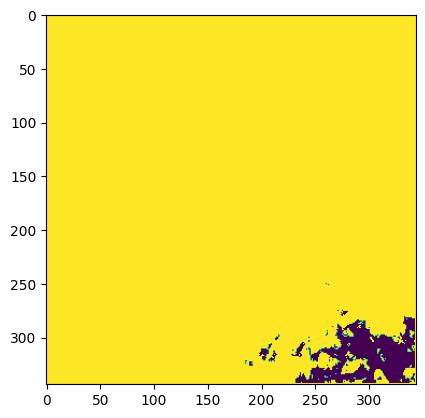

In [37]:
plt.imshow(mov_mask.reshape(*mov_dims))

In [23]:
# Save masked movie dataset
os.makedirs(save_directory, exist_ok=True)
save_path = os.path.join(save_directory, f'M_masked_mov{mov_ind}.pkl')
M_masked.save(save_path)
print(f'Saved to {save_path}')

Saved to /Users/adamkline/Projects/archive/metaneurons/analyses/stimulus predictability/saved/M_masked_mov4.pkl
